# 04 · Baseline LightGBM & Submission Pertama

**Baseline** adalah model acuan: semua 191 fitur v1, parameter LightGBM yang sama seperti di EDA, **tanpa tuning**. Fungsinya menjadi angka pembanding. Setiap eksperimen berikutnya (fitur baru, tuning, ensemble) dinilai dari selisihnya terhadap baseline ini, dengan skema validasi yang **sama persis**.

| # | Pertanyaan |
|---|---|
| Q1 | Berapa KS baseline, dan seberapa stabil antar fold & antar seed? |
| Q2 | Apakah KS validasi terlalu optimistis karena *early stopping*? |
| Q3 | Bagaimana model memisahkan nasabah gagal bayar & lancar (kurva KS, distribusi skor)? |
| Q4 | Seberapa baik model di tiap segmen nasabah (A/B/C)? |
| Q5 | Apa artinya secara bisnis: berapa banyak gagal bayar yang tertangkap di desil berisiko? |
| Q6 | Fitur apa yang paling dipakai model? |
| Q7 | Apakah prediksi test sehat? → tulis & validasi submission pertama |

**Skema validasi** (dipakai di semua eksperimen berikutnya):

- `StratifiedKFold` 5 fold × 3 seed (42, 7, 2024). Proporsi gagal bayar di setiap fold sama (13,6%).
- **OOF (*out-of-fold*)**: setiap baris train diprediksi oleh model yang **tidak** melihat baris itu saat dilatih. KS dari OOF adalah perkiraan KS di data baru. OOF tiga seed dirata-rata.
- **Prediksi test** adalah rata-rata 15 model (3 seed × 5 fold).
- Notebook 03 menunjukkan train dan test berasal dari populasi yang sama, sehingga KS OOF adalah perkiraan yang jujur untuk leaderboard.

> Waktu jalan ±5–6 menit di 2 core CPU. Angka di bawah berasal dari file e-commerce **sampling**. Dengan file penuh, KS Anda diperkirakan ±0,01 lebih tinggi (EDA 5: 0,518 vs 0,507).

In [1]:
import json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import ks_2samp
import eda_utils as E
import features as F
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
FEATURES, CATS = meta["features"], meta["categorical"]
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
SRC_COLOR = dict(zip(F.FEATURE_GROUPS, E.SERIES[:5]))
print(f"train {train.shape} | test {test.shape} | {len(FEATURES)} fitur | e-commerce: {meta['ecommerce_source']}")
print("Parameter LightGBM:", {k: v for k, v in M.LGB_PARAMS.items() if k != "verbose"})

train (70000, 194) | test (30000, 193) | 191 fitur | e-commerce: ecommerce_transactions.csv
Parameter LightGBM: {'objective': 'binary', 'learning_rate': 0.03, 'num_leaves': 31, 'min_child_samples': 100, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'n_estimators': 5000}


## Q1. Berapa KS baseline, dan seberapa stabil?

`train_lgb_cv` melatih 15 model. Setiap model berhenti menambah pohon ketika AUC di fold validasinya tidak membaik selama 100 ronde (*early stopping*).

In [2]:
SEEDS = (42, 7, 2024)
res = M.train_lgb_cv(train, test, FEATURES, CATS, seeds=SEEDS)

seed 42: KS OOF 0.5178  (51s)
seed 7: KS OOF 0.5186  (114s)
seed 2024: KS OOF 0.5176  (173s)
KS OOF rata-rata 3 seed: 0.5195 | per seed: 0.5178, 0.5186, 0.5176


In [3]:
folds = res["folds"]
by_seed = (folds.group_by("seed", maintain_order=True)
                .agg(ks_fold_rata2=pl.col("ks").mean(), ks_fold_sd=pl.col("ks").std(),
                     ks_fold_min=pl.col("ks").min(), ks_fold_maks=pl.col("ks").max(),
                     iterasi_median=pl.col("best_iter").median())
                .with_columns(ks_oof_seed=pl.Series([res["ks_by_seed"][s] for s in SEEDS])))
print(f"KS OOF (rata-rata OOF 3 seed) : {res['ks_oof']:.4f}")
print(f"KS OOF per seed               : " + ", ".join(f"{v:.4f}" for v in res["ks_by_seed"].values())
      + f"  (sebaran {max(res['ks_by_seed'].values()) - min(res['ks_by_seed'].values()):.4f})")
print(f"AUC OOF                       : {E.auc_stat(y, res['oof']):.4f}")
print(f"KS per fold (15 model)        : rata-rata {folds['ks'].mean():.4f} ± {folds['ks'].std():.4f} (SD)")
by_seed.with_columns(pl.col(pl.Float64).round(4))

KS OOF (rata-rata OOF 3 seed) : 0.5195
KS OOF per seed               : 0.5178, 0.5186, 0.5176  (sebaran 0.0010)
AUC OOF                       : 0.8424
KS per fold (15 model)        : rata-rata 0.5206 ± 0.0096 (SD)


seed,ks_fold_rata2,ks_fold_sd,ks_fold_min,ks_fold_maks,iterasi_median,ks_oof_seed
i64,f64,f64,f64,f64,f64,f64
42,0.5204,0.0097,0.5107,0.531,296.0,0.5178
7,0.5203,0.0066,0.5103,0.5268,362.0,0.5186
2024,0.5212,0.0136,0.5,0.5306,318.0,0.5176


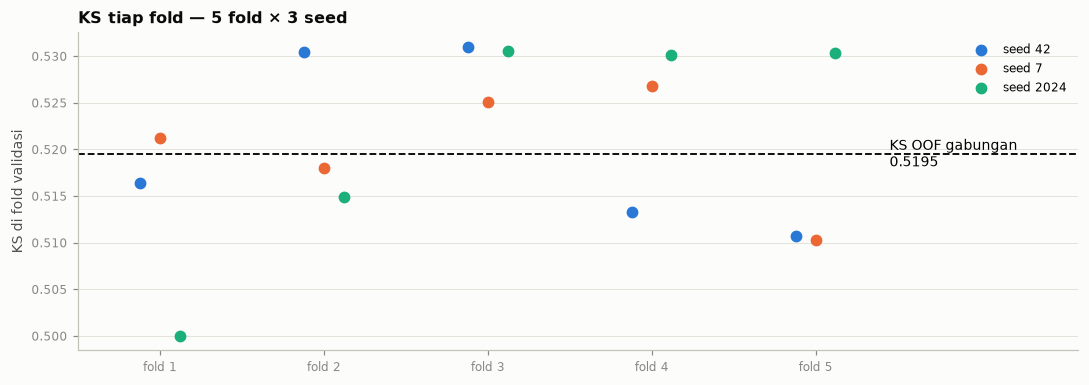

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, s in enumerate(SEEDS):
    f = folds.filter(pl.col("seed") == s)
    ax.scatter(f["fold"] + (i - 1) * 0.12, f["ks"], color=E.SERIES[i], s=45, label=f"seed {s}", zorder=3)
ax.axhline(res["ks_oof"], color="black", lw=1.2, ls="--")
ax.text(5.45, res["ks_oof"], f"KS OOF gabungan\n{res['ks_oof']:.4f}", va="center", fontsize=9)
ax.set_xticks(range(1, 6), [f"fold {k}" for k in range(1, 6)])
ax.set_xlim(0.5, 6.6)
ax.set_ylabel("KS di fold validasi")
ax.set_title("KS tiap fold — 5 fold × 3 seed", loc="left")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

**Cara membaca** (angka dari run saya, e-commerce sampling):

- **KS OOF baseline = 0,507** (AUC 0,836). Ini sama dengan model satu seed di EDA 6 (0,506). 11 fitur gabungan tambahan di v1 tidak banyak mengubah skor, sesuai temuan EDA bahwa informasinya sudah ada di fitur penyusunnya.
- Setiap titik adalah KS satu model pada 14.000 baris yang tidak dilihatnya saat dilatih. Rentangnya 0,488–0,525 (SD ±0,011). Ini **bukan** kualitas model yang berubah-ubah, melainkan noise sampling karena hanya ~1.900 nasabah gagal bayar per fold. Besarnya sama dengan noise leaderboard publik (EDA 6, Q7). Satu fold yang "jelek" tidak berarti apa-apa.
- Yang dipakai untuk membandingkan eksperimen adalah **KS OOF gabungan** (garis putus-putus) karena memakai seluruh 70.000 baris. KS per seed berkisar 0,504–0,508 (sebaran 0,004) **hanya karena cara membagi fold berbeda**. Itulah alasan ambang ±0,005: perubahan yang lebih kecil tidak bisa dibedakan dari pembagian fold yang berbeda.

## Q2. Apakah KS validasi terlalu optimistis karena *early stopping*?

*Early stopping* memilih jumlah pohon berdasarkan AUC di fold validasi, sehingga fold validasi ikut "dipakai" untuk satu keputusan. Ini bisa membuat KS OOF sedikit optimistis.

Untuk mengukurnya, latih ulang seed 42 dengan **jumlah pohon tetap**, yaitu median iterasi terbaik dari Q1, tanpa melihat fold validasi sama sekali. Pembagian fold-nya sama persis (seed sama), jadi perbandingannya berpasangan.

In [5]:
n_fixed = int(np.median(res["best_iters"]))
res_fixed = M.train_lgb_cv(train, test, FEATURES, CATS, seeds=(42,), early_stopping=None,
                           params={"n_estimators": n_fixed}, verbose=False)
ks_es, ks_fx = res["ks_by_seed"][42], res_fixed["ks_oof"]
print(f"Seed 42 — early stopping per fold     : KS OOF {ks_es:.4f}")
print(f"Seed 42 — {n_fixed} pohon tetap (jujur)  : KS OOF {ks_fx:.4f}")
print(f"Selisih (optimisme early stopping)    : {ks_es - ks_fx:+.4f}")

Seed 42 — early stopping per fold     : KS OOF 0.5178
Seed 42 — 299 pohon tetap (jujur)  : KS OOF 0.5166
Selisih (optimisme early stopping)    : +0.0012


**Cara membaca:** di run saya, optimismenya **+0,002** (0,5079 → 0,5060), lebih kecil dari sebaran antar seed (0,004). Jadi *early stopping* tidak membuat skor validasi menipu. Optimisme ini juga kurang lebih sama untuk semua eksperimen, sehingga perbandingan antar eksperimen tetap adil.

Kalau nanti dilakukan tuning yang agresif (ratusan percobaan), optimisme seperti ini bisa menumpuk. Saat itu skor akhir perlu dicek ulang dengan jumlah pohon tetap.

## Q3. Bagaimana model memisahkan nasabah gagal bayar & lancar?

KS adalah **jarak vertikal terbesar** antara dua kurva kumulatif: proporsi nasabah gagal bayar (bad) dan nasabah lancar (good) yang skornya di bawah ambang tertentu. Grafik kiri memakai sumbu-x "persentil populasi" agar mudah dibaca: titik x = 60% berarti 60% aplikasi dengan skor terendah.

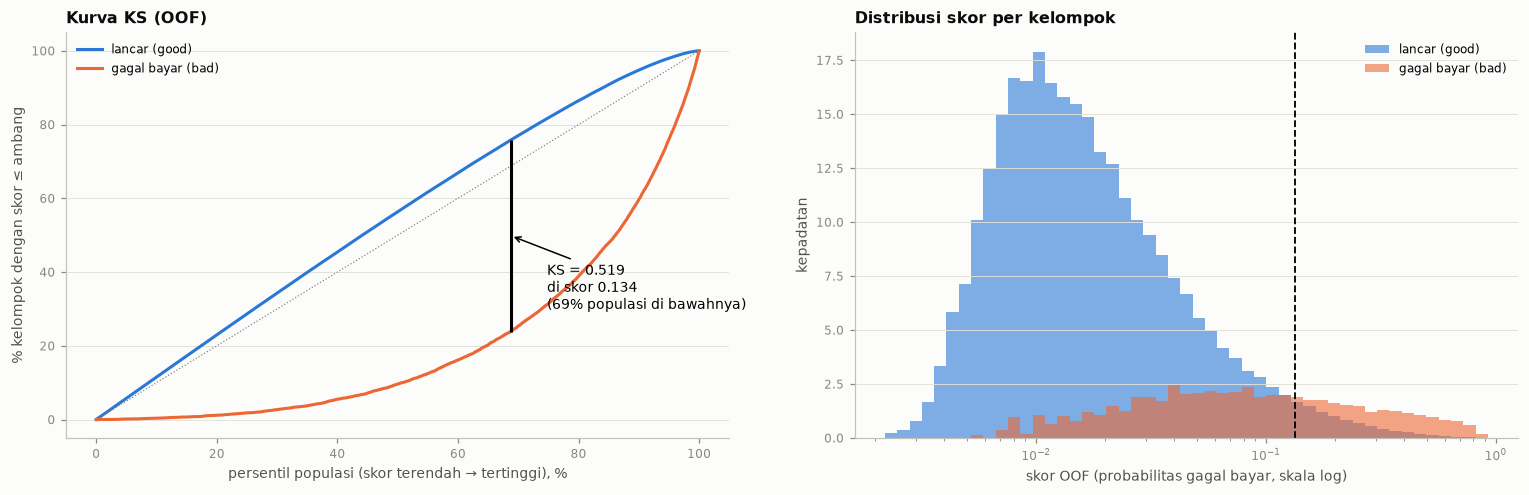

Ambang KS 0.134: 69% populasi di bawahnya — berisi 76% nasabah lancar dan 24% nasabah gagal bayar


In [6]:
oof = res["oof"]
thr, cdf_bad, cdf_good, i_max = M.ks_curve(y, oof)
pop = (np.searchsorted(np.sort(oof), thr, side="right")) / len(oof) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
ax.plot(pop, cdf_good * 100, color=E.SERIES[0], lw=2, label="lancar (good)")
ax.plot(pop, cdf_bad * 100, color=E.SERIES[1], lw=2, label="gagal bayar (bad)")
ax.plot([0, 100], [0, 100], color="grey", lw=0.8, ls=":")
ax.vlines(pop[i_max], cdf_bad[i_max] * 100, cdf_good[i_max] * 100, color="black", lw=2)
ax.annotate(f"KS = {cdf_good[i_max] - cdf_bad[i_max]:.3f}\n"
            f"di skor {thr[i_max]:.3f}\n({pop[i_max]:.0f}% populasi di bawahnya)",
            xy=(pop[i_max], (cdf_bad[i_max] + cdf_good[i_max]) * 50), xytext=(pop[i_max] + 6, 30),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)
ax.set_xlabel("persentil populasi (skor terendah → tertinggi), %")
ax.set_ylabel("% kelompok dengan skor ≤ ambang")
ax.set_title("Kurva KS (OOF)", loc="left"); ax.legend(loc="upper left")
ax = axes[1]
bins = np.logspace(np.log10(max(oof.min(), 1e-3)), np.log10(oof.max()), 50)
ax.hist(oof[y == 0], bins=bins, density=True, alpha=0.6, color=E.SERIES[0], label="lancar (good)")
ax.hist(oof[y == 1], bins=bins, density=True, alpha=0.6, color=E.SERIES[1], label="gagal bayar (bad)")
ax.axvline(thr[i_max], color="black", lw=1.2, ls="--")
ax.set_xscale("log"); ax.set_xlabel("skor OOF (probabilitas gagal bayar, skala log)")
ax.set_ylabel("kepadatan"); ax.set_title("Distribusi skor per kelompok", loc="left"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Ambang KS {thr[i_max]:.3f}: {pop[i_max]:.0f}% populasi di bawahnya — berisi {cdf_good[i_max]:.0%} nasabah lancar "
      f"dan {cdf_bad[i_max]:.0%} nasabah gagal bayar")

**Cara membaca:**

- **Kiri:** kurva biru (lancar) naik lebih cepat karena nasabah lancar terkumpul di skor rendah. Kurva oranye (gagal bayar) baru naik di skor tinggi. Titik jarak terbesar adalah KS, dan posisinya menunjukkan ambang tempat model paling tajam memisahkan kedua kelompok.
- Di run saya, pemisahan terbesar terjadi di skor ≈ 0,12. Di bawah ambang itu ada 65% populasi, berisi 72% nasabah lancar tetapi hanya 22% nasabah gagal bayar: 72% − 22% ≈ KS 0,507.
- **Kanan:** dua distribusi skor yang tumpang tindih. Garis putus-putus (ambang KS) jatuh tepat di titik kedua distribusi berpotongan. KS hanya peduli **urutan** skor, jadi menggeser atau meregangkan skor (misalnya kalibrasi) tidak mengubah KS. Ini sebabnya rank-averaging aman dipakai saat ensemble nanti.

## Q4. Seberapa baik di tiap segmen?

Dibandingkan dengan model satu seed di EDA 6 (180 fitur, sebelum 11 fitur gabungan v1 ditambahkan).

In [7]:
EDA6 = {"SEMUA": 0.5056, "A": 0.4655, "B": 0.4747, "C": 0.5246}
seg_tab = (M.segment_ks(y, oof, SEG)
             .with_columns(ks_eda6=pl.col("segment").str.slice(0, 1).replace({"S": "SEMUA"})
                                     .replace_strict(EDA6, default=None, return_dtype=pl.Float64))
             .with_columns(pl.col("default_rate").round(4), selisih=pl.col("ks") - pl.col("ks_eda6"))
             .with_columns(pl.col("ks", "ks_eda6", "selisih").round(4)))
seg_tab

segment,n,default_rate,ks,ks_eda6,selisih
str,i64,f64,f64,f64,f64
"""SEMUA""",70000,0.1358,0.5195,0.5056,0.0139
"""A_no_history""",21000,0.1172,0.4946,0.4655,0.0291
"""B_apps_no_installments""",2688,0.1551,0.5161,0.4747,0.0414
"""C_has_installments""",46312,0.1431,0.5313,0.5246,0.0067


**Cara membaca:**

- **Segmen C** (ada riwayat cicilan, 66%) paling mudah diurutkan (KS 0,527), karena keterlambatan bayar di masa lalu adalah sinyal terkuat. **Segmen A** (tanpa riwayat, 30%) tetap mencapai 0,471 berkat e-commerce dan biro.
- KS per segmen **tidak** dirata-rata menjadi KS total. KS total juga ikut terbantu oleh perbedaan tingkat risiko **antar** segmen.
- Semua selisih terhadap EDA 6 masih dalam batas noise. Segmen B (2.688 baris, ~420 gagal bayar) punya noise terbesar, sehingga selisih −0,009 di sana tidak berarti apa-apa.

## Q5. Arti bisnis: desil risiko

Urutkan semua aplikasi train dari skor OOF tertinggi ke terendah, lalu bagi menjadi 10 kelompok sama besar. Desil 1 adalah 10% aplikasi paling berisiko.

In [8]:
lift = M.lift_table(y, oof, q=10)
lift.with_columns(pl.col("skor_min", "skor_max", "default_rate", "lift").round(3),
                  pl.col("pct_default_kumulatif", "pct_populasi_kumulatif").round(1))

desil,n,skor_min,skor_max,n_default,default_rate,lift,pct_default_kumulatif,pct_populasi_kumulatif
i64,u32,f64,f64,i64,f64,f64,f64,f64
1,7000,0.377,0.924,3834,0.548,4.033,40.3,10.0
2,7000,0.219,0.377,1977,0.282,2.08,61.1,20.0
3,7000,0.141,0.219,1287,0.184,1.354,74.7,30.0
4,7000,0.094,0.141,874,0.125,0.919,83.9,40.0
5,7000,0.063,0.094,620,0.089,0.652,90.4,50.0
6,7000,0.043,0.063,391,0.056,0.411,94.5,60.0
7,7000,0.03,0.043,268,0.038,0.282,97.3,70.0
8,7000,0.02,0.03,145,0.021,0.153,98.8,80.0
9,7000,0.012,0.02,77,0.011,0.081,99.6,90.0


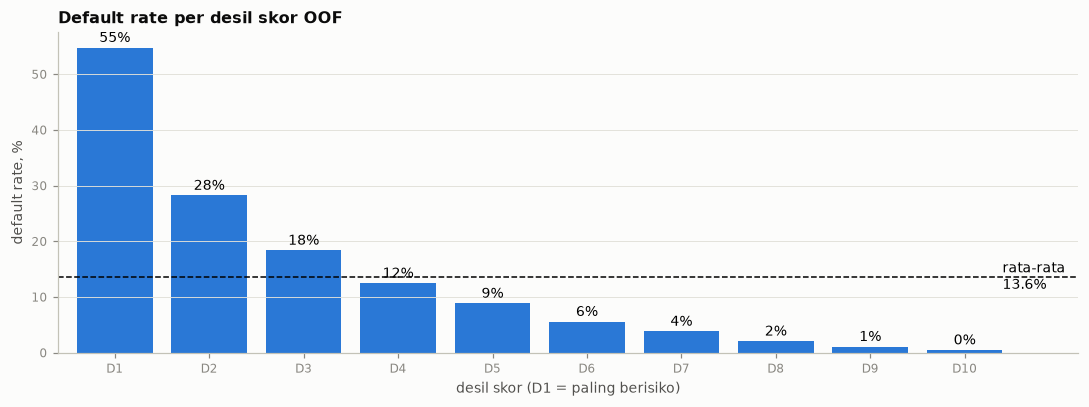

10% aplikasi paling berisiko berisi 40% dari semua gagal bayar; 30% teratas berisi 75%.


In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(lift["desil"], lift["default_rate"] * 100, color=E.C_RATE)
ax.axhline(y.mean() * 100, color="black", ls="--", lw=1)
ax.text(10.4, y.mean() * 100, f"rata-rata\n{y.mean():.1%}", va="center", fontsize=9)
for d, r, c in zip(lift["desil"], lift["default_rate"], lift["pct_default_kumulatif"]):
    ax.text(d, r * 100 + 1, f"{r:.0%}", ha="center", fontsize=9)
ax.set_xticks(range(1, 11), [f"D{d}" for d in range(1, 11)])
ax.set_xlim(0.4, 11.2)
ax.set_xlabel("desil skor (D1 = paling berisiko)"); ax.set_ylabel("default rate, %")
ax.set_title("Default rate per desil skor OOF", loc="left")
plt.tight_layout(); plt.show()
top10, top30 = lift["pct_default_kumulatif"][0], lift["pct_default_kumulatif"][2]
print(f"10% aplikasi paling berisiko berisi {top10:.0f}% dari semua gagal bayar; 30% teratas berisi {top30:.0f}%.")

**Cara membaca:**

- Default rate turun secara **monoton**, dari 53% di D1 ke 0,6% di D10. Tidak ada desil yang "naik di tengah", jadi model mengurutkan dengan konsisten di seluruh rentang skor.
- D1 berisiko ~4× rata-rata (lift 3,9), D10 berisiko ~1/24 dari rata-rata.
- Kolom `pct_default_kumulatif` adalah ukuran praktisnya: menolak 10% aplikasi paling berisiko menghindari **39%** gagal bayar, dan menolak 30% menghindari **74%**.

## Q6. Fitur apa yang paling dipakai model?

*Gain importance* adalah total perbaikan loss dari semua split yang memakai fitur itu, dijumlahkan atas 15 model. **Catatan penting:** gain ≠ kontribusi unik. Dua fitur yang mirip berbagi gain, dan membuang salah satunya bisa tidak berpengaruh. Kontribusi unik per sumber sudah diukur lewat ablation di EDA 6 (Q3).

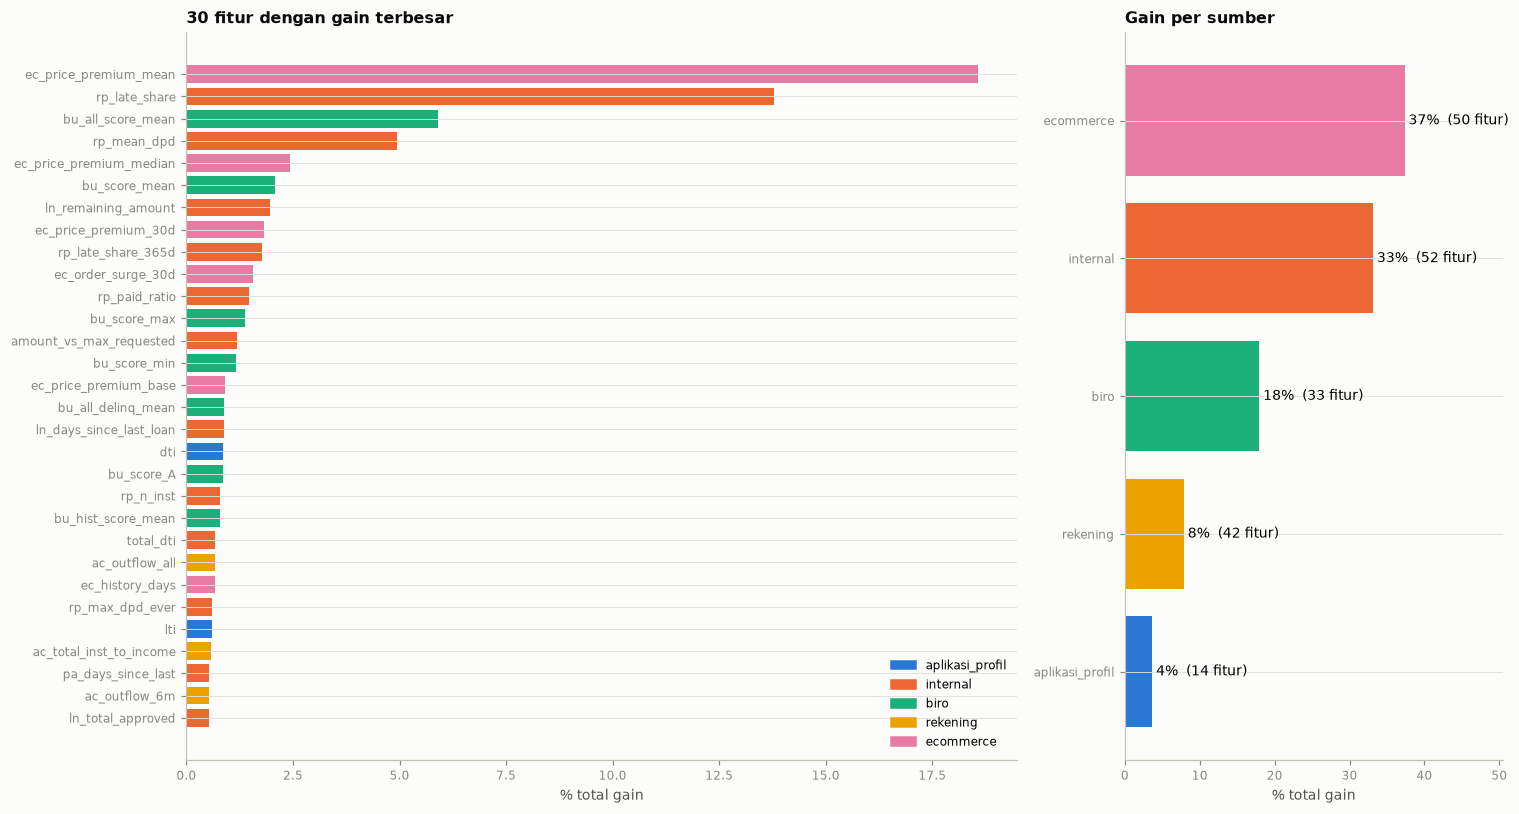

sumber,gain_pct,n_fitur,n_fitur_top30
str,f64,u32,u32
"""ecommerce""",37.4,50,6
"""internal""",33.1,52,12
"""biro""",18.0,33,7
"""rekening""",7.9,42,3
"""aplikasi_profil""",3.7,14,2


In [10]:
imp = res["importance"].with_columns(sumber=pl.Series([F.feature_group(c) for c in res["importance"]["feature"]]))
top = imp.head(30).reverse()
by_src = (imp.group_by("sumber").agg(gain_pct=pl.col("gain_pct").sum(), n_fitur=pl.len(),
                                     n_fitur_top30=pl.col("feature").is_in(imp.head(30)["feature"].to_list()).sum())
             .sort("gain_pct", descending=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.barh(top["feature"], top["gain_pct"], color=[SRC_COLOR[s] for s in top["sumber"]])
ax.set_xlabel("% total gain"); ax.set_title("30 fitur dengan gain terbesar", loc="left")
ax.legend(handles=[Patch(color=SRC_COLOR[g], label=g) for g in F.FEATURE_GROUPS], loc="lower right")
ax = axes[1]
bs = by_src.reverse()
ax.barh(bs["sumber"], bs["gain_pct"], color=[SRC_COLOR[s] for s in bs["sumber"]])
for s, g, n in zip(bs["sumber"], bs["gain_pct"], bs["n_fitur"]):
    ax.text(g + 0.5, s, f"{g:.0f}%  ({n} fitur)", va="center", fontsize=9)
ax.set_xlim(0, by_src["gain_pct"].max() * 1.35)
ax.set_xlabel("% total gain"); ax.set_title("Gain per sumber", loc="left")
plt.tight_layout(); plt.show()
by_src.with_columns(pl.col("gain_pct").round(1))

**Cara membaca:**

- Urutan teratas sejalan dengan EDA: keterlambatan bayar internal (`rp_late_share`, 17%), *price premium* e-commerce (`ec_price_premium_mean`, 14%), dan skor biro rata-rata semua laporan (`bu_all_score_mean`, 6%).
- **Gain per sumber ≠ nilai unik sumber.** Rekening mendapat 8% gain, tetapi ablation di EDA 6 menunjukkan membuang rekening hampir tidak mengubah KS: informasinya tumpang tindih dengan sumber lain. Sebaliknya, e-commerce (32% gain) adalah sumber dengan kontribusi unik terbesar (−0,08 KS bila dibuang). Untuk memutuskan apakah suatu fitur berguna, ukur dengan CV (dengan vs tanpa), bukan dengan importance.
- Puluhan fitur di ekor daftar (gain < 0,3%) tidak merugikan. EDA 6 Q4 menunjukkan 40 fitur teratas sudah setara dengan set penuh, jadi pemangkasan fitur bukan prioritas.

## Q7. Apakah prediksi test sehat? → Submission pertama

Sebelum dikirim, prediksi test harus mirip dengan OOF: rata-rata dekat default rate train, rentang serupa, dan tidak ada nilai aneh.

Satu perbedaan yang wajar: prediksi test adalah rata-rata 15 model, sedangkan setiap OOF rata-rata 3 model. Akibatnya prediksi test sedikit lebih "halus" (nilai minimum & maksimum sedikit lebih ke tengah). Ini tidak mengubah urutan.

In [11]:
tp = res["test_pred"]
qs = [0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
sanity = pl.DataFrame({
    "statistik": ["rata-rata"] + [f"kuantil {q:.0%}" for q in qs] + ["min", "maks"],
    "oof_train": [oof.mean()] + list(np.quantile(oof, qs)) + [oof.min(), oof.max()],
    "prediksi_test": [tp.mean()] + list(np.quantile(tp, qs)) + [tp.min(), tp.max()],
}).with_columns(pl.col("oof_train", "prediksi_test").round(4))
print(f"Default rate train: {y.mean():.4f} | KS distribusi OOF vs test: {ks_2samp(oof, tp).statistic:.4f}")
sanity

Default rate train: 0.1358 | KS distribusi OOF vs test: 0.0048


statistik,oof_train,prediksi_test
str,f64,f64
"""rata-rata""",0.1344,0.1351
"""kuantil 1%""",0.0054,0.0054
"""kuantil 10%""",0.012,0.012
"""kuantil 25%""",0.0243,0.0241
"""kuantil 50%""",0.0631,0.0631
"""kuantil 75%""",0.1749,0.1758
"""kuantil 90%""",0.3775,0.3814
"""kuantil 99%""",0.7457,0.7418
"""min""",0.0022,0.0029


In [12]:
run_meta = M.save_run("lgbm_v1", train, test, res, extra=dict(
    feature_version="v1", ecommerce_source=meta["ecommerce_source"],
    ks_fixed_iter_seed42=ks_fx, n_fixed_iter=n_fixed,
    ks_by_segment={r["segment"]: r["ks"] for r in seg_tab.iter_rows(named=True)}))
print("Run tersimpan:", run_meta)

ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
sub = M.make_submission(test["application_id"], tp, ss, M.SUB_DIR / "sub_v1_lgbm_baseline.csv")
sub.head(5)

Run tersimpan: d:\LOMBA\LOGIKA\data\preds\lgbm_v1_meta.json
✅ kolom tepat [application_id, default_probability]
✅ jumlah baris = sample_submission
✅ application_id unik
✅ semua ID test ada & tidak ada ID asing
✅ probabilitas finite
✅ probabilitas dalam [0, 1]
✅ prediksi tidak konstan
Tersimpan: d:\LOMBA\LOGIKA\submissions\sub_v1_lgbm_baseline.csv  (30,000 baris)


application_id,default_probability
str,f64
"""A_779e4e5a0ca90902""",0.024529
"""A_289cbaf13ec58feb""",0.107604
"""A_172169d79a3f4a35""",0.018536
"""A_51ff46a3e1427786""",0.616388
"""A_bd7e505dcbebaf89""",0.166885


**Satu pemeriksaan lagi, langsung dari file CSV** (bukan dari objek di memori), dengan aturan yang sama seperti evaluator kompetisi:

In [13]:
chk = pl.read_csv(M.SUB_DIR / "sub_v1_lgbm_baseline.csv")
print("kolom      :", chk.columns)
print("baris      :", chk.height, "| ID unik:", chk["application_id"].n_unique())
print("ID cocok   :", set(chk["application_id"]) == set(ss["application_id"]))
print("rentang    :", chk["default_probability"].min(), "–", chk["default_probability"].max())
print("null / NaN :", chk["default_probability"].null_count(), "/", chk["default_probability"].is_nan().sum())

kolom      : ['application_id', 'default_probability']
baris      : 30000 | ID unik: 30000
ID cocok   : True
rentang    : 0.002892570778078038 – 0.9099227307753992
null / NaN : 0 / 0
